# approvals_book

**Knowledge & Search Platform — approvals demo (illustrative, made-up data)**

Picks up where `ingestion_book` ends. Document 2 (`PHARM-OUTREACH-SCRIPT v1.7`) has been split, tagged and compared with the approved baseline (`RX-EDU-SCRIPT v3.2`). Each finding now goes through an approvals workflow built with **LangGraph**:

1. **AI decides** only the mechanical case: an exact duplicate is linked automatically.
2. **Every other finding pauses** for a named human. Legal wording, contradictions and stale content wait for Legal; variants, merges and new operational units wait for the author.
3. **A role check** refuses a decision from the wrong role, then waits again.
4. **Approved changes are published to Chroma** as new units or new versions; the old version is marked superseded. Rejected items are sent back and nothing changes.
5. **Every step is saved,** so each decision has an audit trail.

**Files needed:** `pipeline.py` (in this folder) and, in `../ingestion/` or this folder, `RX-EDU-SCRIPT_v3.2.md`, `PHARM-OUTREACH-SCRIPT_v1.7.md`, `knowledge_ontology_v1.json`.

In [1]:
# Setup: installs Chroma and LangGraph if missing, and checks the files are reachable.
import importlib.util, os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
for pkg in ["chromadb", "langgraph"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

NEEDED = ["pipeline.py", "RX-EDU-SCRIPT_v3.2.md", "PHARM-OUTREACH-SCRIPT_v1.7.md", "knowledge_ontology_v1.json"]
found = lambda f: any((d / f).exists() for d in [Path("."), Path("../ingestion")])
missing = [f for f in NEEDED if not found(f)]
if missing and IN_COLAB:
    from google.colab import files
    print("Upload these files:", ", ".join(missing))
    files.upload()
    missing = [f for f in NEEDED if not found(f)]
print("Missing files: " + ", ".join(missing) if missing else "All files present.")

if IN_COLAB and not os.getenv("ANTHROPIC_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
    except Exception:
        pass

All files present.


## 1. Ingestion results (from `ingestion_book`)

Runs the same pipeline as the ingestion notebook, without its displays: document 1 is published as the approved baseline, document 2 is judged against it.

In [2]:
import pipeline as P
from IPython.display import display, HTML
import html

run = P.run_ingestion()
findings = run["findings"]
FINDINGS = {f["unit"]["uid"]: f for f in findings}
counts = {}
for f in findings:
    counts[f["category"]] = counts.get(f["category"], 0) + 1
print(f"Baseline in Chroma: {P.store.count()} published units from {run['meta1']['Document ID']} v{run['meta1']['Version']}")
print(f"Findings to process from {run['meta2']['Document ID']} v{run['meta2']['Version']}: {len(findings)}\n")
display(HTML(P.CSS + "<div class='card'>" + " &nbsp; ".join(
    f"{P.pill(c.replace('_', ' ').lower(), P.ACTION[c][0])} <b>{n}</b>" for c, n in counts.items()) + "</div>"))

Baseline in Chroma: 18 published units from RX-EDU-SCRIPT v3.2
Findings to process from PHARM-OUTREACH-SCRIPT v1.7: 21



## 2. The approvals graph

| Node | Who acts | What it does |
|---|---|---|
| `route` | AI decides | Sends exact duplicates to `auto_link`, everything else to `human_review` |
| `auto_link` | AI decides | Links the duplicate to the approved unit. No human needed |
| `human_review` | **Human only** | Pauses the graph and waits for a decision from the named reviewer |
| `check_role` | Rule | Accepts the decision only from the required role; otherwise `refuse` |
| `refuse` | Rule | Logs the refused attempt and goes back to `human_review` |
| `apply` | System | Carries out the decision in the knowledge store |

**What a decision does**

| Finding | Reviewer | Approve | Reject |
|---|---|---|---|
| Exact duplicate | AI | — (linked automatically) | — |
| Legal wording differs | Legal | New wording becomes v2 of the unit, for every channel | Approved wording stays; document sent back |
| Contradiction | Legal | New fact becomes v2 of the unit | Approved fact stands; document sent back |
| Stale | Legal | Confirmed stale: not published, author asked to fix | Flag dismissed: published |
| Variant | Author | Published as a scoped variant | Sent back |
| Same meaning | Author | Merged: the approved unit also cites this document | Sent back |
| New unit | Legal or author, by compliance class | Published | Sent back |

In [3]:
import itertools
from datetime import datetime
from typing import TypedDict, Literal, Optional
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

REVIEWER = {"LEGAL_WORDING_DIFFERS": "Legal", "CONTRADICTION": "Legal", "STALE": "Legal",
            "VARIANT": "Author", "SAME_MEANING": "Author", "EXACT_DUPLICATE": None}

def reviewer_for(f):
    if f["category"] == "NEW_UNIT":
        return "Legal" if f["unit"]["approval_gate"] == "legal_approver" else "Author"
    return REVIEWER[f["category"]]

EFFECT = {
    ("EXACT_DUPLICATE", "auto"):        "Linked: the approved unit now also cites this document",
    ("LEGAL_WORDING_DIFFERS", "approve"): "New wording published as v2 for every channel; v1 superseded",
    ("LEGAL_WORDING_DIFFERS", "reject"):  "Approved wording stays live; document sent back to use it",
    ("CONTRADICTION", "approve"):       "New fact published as v2; v1 superseded",
    ("CONTRADICTION", "reject"):        "Approved fact stands; document sent back for correction",
    ("STALE", "approve"):               "Confirmed stale: not published; author asked to replace it",
    ("STALE", "reject"):                "Flag dismissed: published as its own unit",
    ("VARIANT", "approve"):             "Published as a scoped variant",
    ("VARIANT", "reject"):              "Not published; sent back to author",
    ("SAME_MEANING", "approve"):        "Merged: the approved unit now also cites this document",
    ("SAME_MEANING", "reject"):         "Not merged; sent back to author",
    ("NEW_UNIT", "approve"):            "Published as a new unit",
    ("NEW_UNIT", "reject"):             "Not published; sent back to author",
}

class Review(TypedDict, total=False):
    uid: str
    category: str
    reviewer: Optional[str]
    decision: str
    by: str
    role: str
    note: str
    effect: str
    approval_id: str
    log: list

approval_ids = itertools.count(1)
now = lambda: datetime.now().strftime("%H:%M:%S")

# ---- knowledge-store changes -------------------------------------------------
def meta_of(uid):
    r = P.store.get(ids=[uid])
    return r["metadatas"][0]

def add_citation(uid, source_uid):
    md = meta_of(uid)
    cites = [c for c in md.get("also_in", "").split(",") if c] + [source_uid]
    P.store.update(ids=[uid], metadatas=[{**md, "also_in": ",".join(cites)}])

def publish_unit(u, s, aid, variant_of=""):
    md = {k: u[k] for k in ("doc_id", "doc_version", "section", "title", "unit_type", "topic", "kb",
                            "compliance_class", "plan_year", "channel", "is_verbatim")}
    md |= {"status": "published", "approved_by": f"{s['by']} ({s['reviewer']})", "approval_id": aid,
           "unit_version": 1, "variant_of": variant_of}
    P.store.add(ids=[u["uid"]], embeddings=P.embed([u["text"]]), documents=[u["text"]], metadatas=[md])

def new_version(old_uid, u, s, aid):
    md = meta_of(old_uid)
    v = int(md.get("unit_version", 1)) + 1
    new_id = f"{old_uid.split('@')[0]}@v{v}"
    P.store.add(ids=[new_id], embeddings=P.embed([u["text"]]), documents=[u["text"]],
                metadatas=[{**md, "status": "published", "approved_by": f"{s['by']} ({s['reviewer']})",
                            "approval_id": aid, "unit_version": v, "supersedes": old_uid, "source_doc": u["doc_id"]}])
    P.store.update(ids=[old_uid], metadatas=[{**md, "status": "superseded", "superseded_by": new_id}])
    return new_id

# ---- graph nodes -------------------------------------------------------------
def route(s) -> Literal["auto_link", "human_review"]:
    return "auto_link" if s["category"] == "EXACT_DUPLICATE" else "human_review"

def auto_link(s):
    return {"decision": "auto", "by": "AI (rule)", "log": s["log"] + [f"{now()}  AI linked exact duplicate"]}

def human_review(s):
    f = FINDINGS[s["uid"]]
    ans = interrupt({"uid": s["uid"], "finding": s["category"], "reviewer": s["reviewer"], "reason": f["reason"],
                     "matched": f["match"]["uid"] if f["match"] and s["category"] != "NEW_UNIT" else None,
                     "options": ["approve", "reject"]})
    return {"decision": ans["decision"], "by": ans["by"], "role": ans["role"], "note": ans.get("note", ""),
            "log": s["log"] + [f"{now()}  {ans['by']} ({ans['role']}) chose {ans['decision']}"]}

def check_role(s) -> Literal["apply", "refuse"]:
    return "apply" if s["role"] == s["reviewer"] and s["decision"] in ("approve", "reject") else "refuse"

def refuse(s):
    return {"log": s["log"] + [f"{now()}  REFUSED: {s['role']} cannot decide a {s['reviewer']} item; waiting again"]}

def apply(s):
    f = FINDINGS[s["uid"]]
    u, m = f["unit"], f["match"]
    key = (s["category"], s["decision"])
    aid = "—" if s["decision"] == "reject" else "AUTO" if s["decision"] == "auto" else f"APR-{next(approval_ids):04d}"
    detail = ""
    if key in [("EXACT_DUPLICATE", "auto"), ("SAME_MEANING", "approve")]:
        add_citation(m["uid"], u["uid"]); detail = f" ({m['uid']})"
    elif key in [("LEGAL_WORDING_DIFFERS", "approve"), ("CONTRADICTION", "approve")]:
        detail = f" ({new_version(m['uid'], u, s, aid)})"
    elif key in [("VARIANT", "approve"), ("NEW_UNIT", "approve"), ("STALE", "reject")]:
        publish_unit(u, s, aid, variant_of=m["uid"] if key[0] == "VARIANT" else ""); detail = f" ({u['uid']})"
    return {"effect": EFFECT[key] + detail, "approval_id": aid,
            "log": s["log"] + [f"{now()}  applied: {EFFECT[key]}{detail}"]}

g = StateGraph(Review)
for name, fn in [("auto_link", auto_link), ("human_review", human_review), ("refuse", refuse), ("apply", apply)]:
    g.add_node(name, fn)
g.add_conditional_edges(START, route)
g.add_edge("auto_link", "apply")
g.add_conditional_edges("human_review", check_role)
g.add_edge("refuse", "human_review")
g.add_edge("apply", END)
approvals = g.compile(checkpointer=InMemorySaver())
print("Approvals graph compiled with nodes:", [n for n in approvals.get_graph().nodes if not n.startswith("__")])

Approvals graph compiled with nodes: ['auto_link', 'human_review', 'refuse', 'apply']


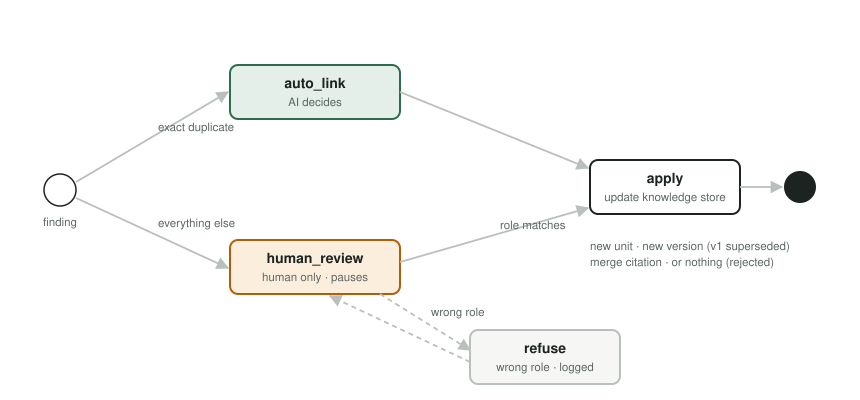

In [4]:
#@title Graph diagram { display-mode: "form" }
from IPython.display import SVG
AMBER, GRAY, INK, MUTED, TEAL = "#b25e09", "#b9c0bb", "#1d2320", "#5c6661", "#2f6b4f"
def box(x, y, w, label, sub, color, fill):
    return (f'<rect x="{x}" y="{y}" width="{w}" height="54" rx="8" fill="{fill}" stroke="{color}" stroke-width="2"/>'
            f'<text x="{x+w/2}" y="{y+23}" text-anchor="middle" font-size="14" font-weight="700" fill="{INK}">{label}</text>'
            f'<text x="{x+w/2}" y="{y+41}" text-anchor="middle" font-size="11.5" fill="{MUTED}">{sub}</text>')
def arrow(x1, y1, x2, y2, label="", dash=False):
    d = ' stroke-dasharray="5 4"' if dash else ""
    t = (f'<text x="{(x1+x2)/2 + 6}" y="{(y1+y2)/2 - 6}" font-size="11.5" fill="{MUTED}">{label}</text>' if label else "")
    return f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="{GRAY}" stroke-width="1.8" marker-end="url(#a)"{d}/>' + t
svg = f"""<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 860 400" width="860" font-family="Helvetica, Arial, sans-serif">
<defs><marker id="a" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto"><path d="M0,0 L10,5 L0,10 z" fill="{GRAY}"/></marker></defs>
<rect width="860" height="400" fill="#ffffff"/>
<circle cx="60" cy="190" r="16" fill="#ffffff" stroke="{INK}" stroke-width="1.5"/><text x="60" y="226" text-anchor="middle" font-size="11.5" fill="{MUTED}">finding</text>
{arrow(76, 182, 228, 92, "exact duplicate")}
{arrow(76, 198, 228, 268, "everything else")}
{box(230, 65, 170, "auto_link", "AI decides", TEAL, "#e3efe8")}
{box(230, 240, 170, "human_review", "human only · pauses", AMBER, "#fbeedd")}
{box(470, 330, 150, "refuse", "wrong role · logged", GRAY, "#f6f7f5")}
{arrow(400, 92, 588, 168)}
{arrow(400, 262, 588, 208, "role matches")}
{arrow(380, 294, 470, 350, "wrong role", True)}
{arrow(470, 362, 330, 296, "", True)}
{box(590, 160, 150, "apply", "update knowledge store", INK, "#ffffff")}
<circle cx="800" cy="187" r="16" fill="{INK}"/>{arrow(740, 187, 782, 187)}
<text x="590" y="250" font-size="11.5" fill="{MUTED}">new unit · new version (v1 superseded)</text>
<text x="590" y="266" font-size="11.5" fill="{MUTED}">merge citation · or nothing (rejected)</text>
</svg>"""
display(SVG(svg))

## 3. Send every finding through the graph

Each finding runs as its own thread. Exact duplicates finish straight away; the rest pause at `human_review`, which builds the review queue below.

In [5]:
def cfg(uid):
    return {"configurable": {"thread_id": uid}}

pending = {}
for uid, f in FINDINGS.items():
    out = approvals.invoke({"uid": uid, "category": f["category"], "reviewer": reviewer_for(f), "log": []}, cfg(uid))
    if "__interrupt__" in out:
        pending[uid] = out["__interrupt__"][0].value

done = [u for u in FINDINGS if u not in pending]
print(f"Finished without a human: {len(done)} · waiting for a decision: {len(pending)}\n")

for who in ["Legal", "Author"]:
    items = [(u, p) for u, p in pending.items() if p["reviewer"] == who]
    rows = "".join(f"<tr><td class='mono'>{u}</td><td>{html.escape(FINDINGS[u]['unit']['title'])}</td>"
                   f"<td>{P.pill(p['finding'].replace('_', ' ').lower(), P.ACTION[p['finding']][0])}</td>"
                   f"<td class='mono'>{p['matched'] or '—'}</td><td>{html.escape(p['reason'])}</td></tr>" for u, p in items)
    display(HTML(P.CSS + f"<div class='card'><h4>{who} queue — {len(items)}</h4><table class='kt'>"
                 "<tr><th>Unit</th><th>Section</th><th>Finding</th><th>Approved unit</th><th>Why</th></tr>" + rows + "</table></div>"))

Finished without a human: 2 · waiting for a decision: 19



Unit,Section,Finding,Approved unit,Why
PHARM-OUTREACH-SCRIPT§3.V1,Voicemail script,new unit,—,No published unit is close enough.
PHARM-OUTREACH-SCRIPT§5.V1,Recording disclosure,legal wording differs,RX-EDU-SCRIPT§4.V1,"Legal verbatim differs from approved RX-EDU-SCRIPT§4.V1 (LGL-2026-118). The approved version is newer, so the new wording is drift."
PHARM-OUTREACH-SCRIPT§7.V1,Pricing disclaimer,legal wording differs,RX-EDU-SCRIPT§6.V1,"Legal verbatim differs from approved RX-EDU-SCRIPT§6.V1 (LGL-2026-118). The approved version is newer, so the new wording is drift."
PHARM-OUTREACH-SCRIPT§10.G,Mail-order pharmacy (campaign focus),contradiction,RX-EDU-SCRIPT§10.G,"Same subject, different facts: 100-day, 14, 5 (approved) vs 10, 21, 90-day (new)."
PHARM-OUTREACH-SCRIPT§12.G,Drug payment stages,stale,RX-EDU-SCRIPT§11.G,"Mentions retired concept (donut hole, coverage gap); approved unit is plan year 2027."
PHARM-OUTREACH-SCRIPT§14.V1,Do-not-call requests,new unit,—,No published unit is close enough.
PHARM-OUTREACH-SCRIPT§15.V1,Closing,legal wording differs,RX-EDU-SCRIPT§14.V1,"Legal verbatim differs from approved RX-EDU-SCRIPT§14.V1 (LGL-2026-118). The approved version is newer, so the new wording is drift."


Unit,Section,Finding,Approved unit,Why
PHARM-OUTREACH-SCRIPT§1.G,Purpose,variant,RX-EDU-SCRIPT§1.G,Channel-specific content (outbound vs advocate_desktop); both can stand.
PHARM-OUTREACH-SCRIPT§2.G,Opening (outbound),variant,RX-EDU-SCRIPT§5.G,Channel-specific content (outbound vs advocate_desktop); both can stand.
PHARM-OUTREACH-SCRIPT§3.G,Voicemail script,new unit,—,No published unit is close enough.
PHARM-OUTREACH-SCRIPT§4.G,Identity verification,new unit,—,No published unit is close enough.
PHARM-OUTREACH-SCRIPT§6.G,Reason for the call,new unit,—,No published unit is close enough.
PHARM-OUTREACH-SCRIPT§7.G,Pricing disclaimer,new unit,—,No published unit is close enough.
PHARM-OUTREACH-SCRIPT§8.G,Drug tiers,variant,RX-EDU-SCRIPT§7.G,"Figures differ ($45, $47, 2026, 2027) but plan years differ (2026 vs 2027)."
PHARM-OUTREACH-SCRIPT§9.G,Generic drugs,same meaning,RX-EDU-SCRIPT§8.G,"Same subject, no conflicting figures, different wording."
PHARM-OUTREACH-SCRIPT§11.G,Preferred pharmacies,same meaning,RX-EDU-SCRIPT§10.G,"Same subject, no conflicting figures, different wording."
PHARM-OUTREACH-SCRIPT§13.G,Premium and billing questions,new unit,—,No published unit is close enough.


## 4. Humans decide

In a product this is a review screen. Here, each decision is one call to `decide()`, which resumes that finding's paused thread.

First, the role check: the author tries to approve Legal's pricing-disclaimer item. The graph refuses and keeps waiting.

In [6]:
def decide(uid, decision, by, role, note=""):
    out = approvals.invoke(Command(resume={"decision": decision, "by": by, "role": role, "note": note}), cfg(uid))
    if approvals.get_state(cfg(uid)).next:
        print(f"REFUSED  {uid}: {role} cannot decide a {pending[uid]['reviewer']} item. Still waiting.")
    else:
        print(f"{decision.upper():8} {uid}: {out['effect']}")

disclaimer = next(u for u, p in pending.items() if FINDINGS[u]["unit"]["title"] == "Pricing disclaimer" and p["reviewer"] == "Legal")
decide(disclaimer, "approve", by="Maya Ortiz", role="Author")

REFUSED  PHARM-OUTREACH-SCRIPT§7.V1: Author cannot decide a Legal item. Still waiting.


Now the real decisions. **David Reyes (Legal)** keeps the approved v3.2 wording for the pricing disclaimer and closing, but adopts the outreach wording of the recording disclosure as the new standard for every channel. **Maya Ortiz (Knowledge Ops author)** approves the variants and new operational units, and rejects one "same meaning" merge she spots as a real contradiction.

Anything not listed below is approved by its reviewer.

In [7]:
PEOPLE = {"Legal": "David Reyes", "Author": "Maya Ortiz"}

# Decisions that are not a plain approve, matched by (section title, reviewer) so they hold if Claude re-tags units.
OVERRIDES = {
    ("Pricing disclaimer", "Legal"):   ("reject",  "v3.2 wording (LGL-2026-118) stands. Outreach script must use it."),
    ("Closing", "Legal"):              ("reject",  "Keep the approved closing, including 'local time'."),
    ("Recording disclosure", "Legal"): ("approve", "Adopt 'monitored or recorded' as the standard for all channels."),
    ("Mail-order pharmacy (campaign focus)", "Legal"): ("reject", "5 to 7 business days and up to a 100-day supply are current."),
    ("Preferred pharmacies", "Author"): ("reject", "Not the same meaning: preferred copays do not apply at all network pharmacies. Escalate to Legal."),
}

for uid, p in list(pending.items()):
    if not approvals.get_state(cfg(uid)).next:
        continue
    title = FINDINGS[uid]["unit"]["title"]
    decision, note = OVERRIDES.get((title, p["reviewer"]), ("approve", ""))
    if p["finding"] == "LEGAL_WORDING_DIFFERS" and (title, p["reviewer"]) not in OVERRIDES:
        decision, note = "reject", "Keep approved wording."
    decide(uid, decision, by=PEOPLE[p["reviewer"]], role=p["reviewer"], note=note)

APPROVE  PHARM-OUTREACH-SCRIPT§1.G: Published as a scoped variant (PHARM-OUTREACH-SCRIPT§1.G)
APPROVE  PHARM-OUTREACH-SCRIPT§2.G: Published as a scoped variant (PHARM-OUTREACH-SCRIPT§2.G)
APPROVE  PHARM-OUTREACH-SCRIPT§3.V1: Published as a new unit (PHARM-OUTREACH-SCRIPT§3.V1)
APPROVE  PHARM-OUTREACH-SCRIPT§3.G: Published as a new unit (PHARM-OUTREACH-SCRIPT§3.G)
APPROVE  PHARM-OUTREACH-SCRIPT§4.G: Published as a new unit (PHARM-OUTREACH-SCRIPT§4.G)
APPROVE  PHARM-OUTREACH-SCRIPT§5.V1: New wording published as v2 for every channel; v1 superseded (RX-EDU-SCRIPT§4.V1@v2)
APPROVE  PHARM-OUTREACH-SCRIPT§6.G: Published as a new unit (PHARM-OUTREACH-SCRIPT§6.G)
REJECT   PHARM-OUTREACH-SCRIPT§7.V1: Approved wording stays live; document sent back to use it
APPROVE  PHARM-OUTREACH-SCRIPT§7.G: Published as a new unit (PHARM-OUTREACH-SCRIPT§7.G)
APPROVE  PHARM-OUTREACH-SCRIPT§8.G: Published as a scoped variant (PHARM-OUTREACH-SCRIPT§8.G)
APPROVE  PHARM-OUTREACH-SCRIPT§9.G: Merged: the approved un

REJECT   PHARM-OUTREACH-SCRIPT§10.G: Approved fact stands; document sent back for correction
REJECT   PHARM-OUTREACH-SCRIPT§11.G: Not merged; sent back to author
APPROVE  PHARM-OUTREACH-SCRIPT§12.G: Confirmed stale: not published; author asked to replace it
APPROVE  PHARM-OUTREACH-SCRIPT§13.G: Published as a new unit (PHARM-OUTREACH-SCRIPT§13.G)
APPROVE  PHARM-OUTREACH-SCRIPT§14.V1: Published as a new unit (PHARM-OUTREACH-SCRIPT§14.V1)
APPROVE  PHARM-OUTREACH-SCRIPT§14.G: Published as a new unit (PHARM-OUTREACH-SCRIPT§14.G)
REJECT   PHARM-OUTREACH-SCRIPT§15.V1: Approved wording stays live; document sent back to use it
APPROVE  PHARM-OUTREACH-SCRIPT§16.G: Published as a scoped variant (PHARM-OUTREACH-SCRIPT§16.G)


## 5. Decision log

In [8]:
rows = ""
for uid in FINDINGS:
    v = approvals.get_state(cfg(uid)).values
    color = P.ACTION[v["category"]][0]
    dec = {"approve": "#2f6b4f", "reject": "#b42318", "auto": "#5c6661"}[v["decision"]]
    rows += (f"<tr><td class='mono'>{uid}</td><td>{P.pill(v['category'].replace('_', ' ').lower(), color)}</td>"
             f"<td>{P.pill(v['decision'], dec)}</td><td>{html.escape(v['by'])}</td><td class='mono'>{v.get('approval_id', '—')}</td>"
             f"<td>{html.escape(v['effect'])}</td><td>{html.escape(v.get('note', ''))}</td></tr>")
display(HTML(P.CSS + "<table class='kt'><tr><th>Unit</th><th>Finding</th><th>Decision</th><th>By</th><th>Approval</th>"
             "<th>Effect</th><th>Note</th></tr>" + rows + "</table>"))

Unit,Finding,Decision,By,Approval,Effect,Note
PHARM-OUTREACH-SCRIPT§1.G,variant,approve,Maya Ortiz,APR-0001,Published as a scoped variant (PHARM-OUTREACH-SCRIPT§1.G),
PHARM-OUTREACH-SCRIPT§2.G,variant,approve,Maya Ortiz,APR-0002,Published as a scoped variant (PHARM-OUTREACH-SCRIPT§2.G),
PHARM-OUTREACH-SCRIPT§3.V1,new unit,approve,David Reyes,APR-0003,Published as a new unit (PHARM-OUTREACH-SCRIPT§3.V1),
PHARM-OUTREACH-SCRIPT§3.G,new unit,approve,Maya Ortiz,APR-0004,Published as a new unit (PHARM-OUTREACH-SCRIPT§3.G),
PHARM-OUTREACH-SCRIPT§4.V1,exact duplicate,auto,AI (rule),AUTO,Linked: the approved unit now also cites this document (RX-EDU-SCRIPT§3.V1),
PHARM-OUTREACH-SCRIPT§4.G,new unit,approve,Maya Ortiz,APR-0005,Published as a new unit (PHARM-OUTREACH-SCRIPT§4.G),
PHARM-OUTREACH-SCRIPT§5.V1,legal wording differs,approve,David Reyes,APR-0006,New wording published as v2 for every channel; v1 superseded (RX-EDU-SCRIPT§4.V1@v2),Adopt 'monitored or recorded' as the standard for all channels.
PHARM-OUTREACH-SCRIPT§6.G,new unit,approve,Maya Ortiz,APR-0007,Published as a new unit (PHARM-OUTREACH-SCRIPT§6.G),
PHARM-OUTREACH-SCRIPT§7.V1,legal wording differs,reject,David Reyes,—,Approved wording stays live; document sent back to use it,v3.2 wording (LGL-2026-118) stands. Outreach script must use it.
PHARM-OUTREACH-SCRIPT§7.G,new unit,approve,Maya Ortiz,APR-0008,Published as a new unit (PHARM-OUTREACH-SCRIPT§7.G),


## 6. The knowledge store after approvals

Only approved changes reached Chroma. The recording disclosure now has a v2 that every channel picks up, and v1 is kept as superseded for the record.

In [9]:
data = P.store.get(include=["metadatas"])
status = {}
for md_ in data["metadatas"]:
    status[md_["status"]] = status.get(md_["status"], 0) + 1
print(f"Records: {len(data['ids'])}  ·  " + "  ·  ".join(f"{k}: {n}" for k, n in status.items()))
print(f"Baseline units now also cited by document 2: {sum(1 for m in data['metadatas'] if m.get('also_in'))}\n")

rows = ""
for uid, md_ in zip(data["ids"], data["metadatas"]):
    changed = md_["doc_id"] != run["meta1"]["Document ID"] or md_["status"] != "published" or md_.get("also_in") or "@" in uid
    if not changed:
        continue
    what = ("new version" if md_.get("supersedes") else "superseded" if md_["status"] == "superseded"
            else "variant" if md_.get("variant_of") else "cited by doc 2" if md_.get("also_in") else "new unit")
    rows += (f"<tr><td class='mono'>{uid}</td><td>{md_['status']}</td><td>{what}</td><td>{md_.get('approved_by', '')}</td>"
             f"<td class='mono'>{md_.get('approval_id', '')}</td><td class='mono'>{md_.get('supersedes') or md_.get('superseded_by') or md_.get('variant_of') or md_.get('also_in', '')}</td></tr>")
display(HTML(P.CSS + "<table class='kt'><tr><th>Record</th><th>Status</th><th>Change</th><th>Approved by</th><th>Approval</th><th>Linked to</th></tr>" + rows + "</table>"))

Records: 31  ·  published: 30  ·  superseded: 1
Baseline units now also cited by document 2: 3



Record,Status,Change,Approved by,Approval,Linked to
RX-EDU-SCRIPT§3.V1,published,cited by doc 2,Legal (simulated),LGL-2026-118,PHARM-OUTREACH-SCRIPT§4.V1
RX-EDU-SCRIPT§4.V1,superseded,superseded,Legal (simulated),LGL-2026-118,RX-EDU-SCRIPT§4.V1@v2
RX-EDU-SCRIPT§8.G,published,cited by doc 2,Legal (simulated),LGL-2026-118,PHARM-OUTREACH-SCRIPT§9.G
RX-EDU-SCRIPT§14.G,published,cited by doc 2,Legal (simulated),LGL-2026-118,PHARM-OUTREACH-SCRIPT§15.G
PHARM-OUTREACH-SCRIPT§1.G,published,variant,Maya Ortiz (Author),APR-0001,RX-EDU-SCRIPT§1.G
PHARM-OUTREACH-SCRIPT§2.G,published,variant,Maya Ortiz (Author),APR-0002,RX-EDU-SCRIPT§5.G
PHARM-OUTREACH-SCRIPT§3.V1,published,new unit,David Reyes (Legal),APR-0003,
PHARM-OUTREACH-SCRIPT§3.G,published,new unit,Maya Ortiz (Author),APR-0004,
PHARM-OUTREACH-SCRIPT§4.G,published,new unit,Maya Ortiz (Author),APR-0005,
RX-EDU-SCRIPT§4.V1@v2,published,new version,David Reyes (Legal),APR-0006,RX-EDU-SCRIPT§4.V1


**One source, every channel.** Search reads only published units, so an inbound advocate asking about call recording now gets v2, approved for outreach, with no second edit anywhere.

In [10]:
q = "this call may be recorded"
r = P.store.query(query_embeddings=P.embed([q]), n_results=2,
                  where={"$and": [{"kb": {"$in": P.ONTOLOGY["access_policy"]["pharmacy_advocate"]}}, {"status": "published"}]})
for uid, doc, md_ in zip(r["ids"][0], r["documents"][0], r["metadatas"][0]):
    print(f"{uid}  [{md_['status']}, v{md_.get('unit_version', 1)}, {md_['approval_id']}]\n    {doc}\n")

RX-EDU-SCRIPT§4.V1@v2  [published, v2, APR-0006]
    "Please be aware this call may be monitored or recorded for quality purposes."

PHARM-OUTREACH-SCRIPT§6.G  [published, v1, APR-0007]
    "I'm calling to share a few ways you may be able to save on your prescriptions this year. Do you have a few minutes?"

Guidance: If the member says no, offer to call back and record a preferred time. If the member asks to stop receiving calls, follow Section 14.



## 7. Audit trail for one decision

LangGraph saved a checkpoint at every step. Here is the recording disclosure, from the moment it entered the graph to publication.

In [11]:
rec = next(u for u in FINDINGS if FINDINGS[u]["unit"]["title"] == "Recording disclosure")
history = list(approvals.get_state_history(cfg(rec)))[::-1]
print(f"{rec}: {len(history)} checkpoints\n")
for i, snap in enumerate(history):
    nxt = ", ".join(snap.next) or "END"
    print(f"  step {i}: next → {nxt:13} decision={snap.values.get('decision', '—'):8} by={snap.values.get('by', '—')}")
print("\nLog:")
for line in approvals.get_state(cfg(rec)).values["log"]:
    print("  " + line)
print("\nThe disclaimer item, including the refused attempt:")
for line in approvals.get_state(cfg(disclaimer)).values["log"]:
    print("  " + line)

PHARM-OUTREACH-SCRIPT§5.V1: 4 checkpoints

  step 0: next → __start__     decision=—        by=—
  step 1: next → human_review  decision=—        by=—
  step 2: next → apply         decision=approve  by=David Reyes
  step 3: next → END           decision=approve  by=David Reyes

Log:
  18:19:27  David Reyes (Legal) chose approve
  18:19:27  applied: New wording published as v2 for every channel; v1 superseded (RX-EDU-SCRIPT§4.V1@v2)

The disclaimer item, including the refused attempt:
  18:19:27  Maya Ortiz (Author) chose approve
  18:19:27  REFUSED: Author cannot decide a Legal item; waiting again
  18:19:27  David Reyes (Legal) chose reject
  18:19:27  applied: Approved wording stays live; document sent back to use it


## What this shows, and what is simulated

- **The brief's three columns are the graph's structure.** AI decides only exact duplicates; every other path runs through `human_review`, and `check_role` enforces who may decide what.
- **Single source of truth:** approving the recording disclosure once updated what every channel retrieves.
- **Nothing unapproved reaches the store,** and rejected items leave the approved wording live.
- **Simulated:** the reviewers' decisions (cells, not a review screen); state is held in memory, so it resets when the notebook restarts. In production the checkpoints and decision log go to a database.
- **Next:** the drift loop (a revised v3.3 of the source flags its units stale and proposes the fix), and search with citations and a golden set.